# Module 04 — Dark-Store, Rider Intelligence and Recommendations

This notebook completes **PS6 (broad K-Means comparison and refined Haversine DBSCAN demand hotspots)**, **PS7 (exploratory rider segments)**, and **PS8 (three evidence-based management recommendations)**. It builds on the completed PS1–PS5 outputs without changing them.

**Applicability limitation:** The available records describe restaurant food delivery, not quick-commerce grocery operations. Customer delivery locations are used as a proxy for demand zones; cluster centroids are potential zones for investigation, not confirmed optimal dark-store locations. Results should not be generalized to all quick-commerce businesses without validation using actual quick-commerce operational data.

## 1. Imports and Configuration

Set reproducible clustering parameters and use the existing project-relative folders. Matplotlib geographic plots are used when interactive mapping packages are unavailable.

In [1]:
from pathlib import Path
import importlib.util
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from IPython.display import display
import folium
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
SLA_MINUTES = 30
EARTH_RADIUS_KM = 6371.0088
ZONE_K_VALUES = range(2, 16)
RIDER_K_VALUES = range(2, 9)
SILHOUETTE_SAMPLE_SIZE = 2000

ROOT = next(
    (candidate for candidate in (Path.cwd(), Path.cwd().parent)
     if (candidate / "data" / "cleaned_data.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Cannot locate data/cleaned_data.csv relative to the notebook.")

DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
PS6_DIR = OUTPUT_DIR / "ps6"
PS7_DIR = OUTPUT_DIR / "ps7"
PS8_DIR = OUTPUT_DIR / "ps8"
MODEL_DIR = ROOT / "models"
for directory in (PS6_DIR, PS7_DIR, PS8_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
print("Project root:", ROOT)
print("Analytical SLA:", SLA_MINUTES, "minutes (not an official customer promise)")
print("Folium available:", bool(importlib.util.find_spec("folium")))
print("Plotly available:", bool(importlib.util.find_spec("plotly")))

Project root: C:\Users\javed\Desktop\calibo\Manthan
Analytical SLA: 30 minutes (not an official customer promise)
Folium available: True
Plotly available: False


## 2. Load Completed Project Data and Verify Assumptions

Use the PS1 cleaned records to preserve the original missing rider ratings. Reuse PS1 GPS validation flags and PS2's 30-minute label from existing outputs. Confirm the authoritative Module 02 feature report and Module 03 metadata are still consistent; no earlier notebook or source file is modified.

In [2]:
cleaned_path = DATA_DIR / "cleaned_data.csv"
gps_validation_path = DATA_DIR / "final_cleaned_data.csv"
model_ready_path = DATA_DIR / "model_ready_data.csv"
feature_report_path = OUTPUT_DIR / "ps2" / "feature_availability_report.csv"
delay_summary_path = OUTPUT_DIR / "ps2" / "delay_lens_summary.json"
ml_metadata_path = MODEL_DIR / "model_metadata.json"

cleaned = pd.read_csv(cleaned_path, dtype={"ID": "string", "Delivery_person_ID": "string"})
gps_validation = pd.read_csv(gps_validation_path, dtype={"ID": "string"})
model_ready = pd.read_csv(model_ready_path, dtype={"ID": "string"})
feature_report = pd.read_csv(feature_report_path)
with delay_summary_path.open(encoding="utf-8") as file:
    delay_summary = json.load(file)
with ml_metadata_path.open(encoding="utf-8") as file:
    ml_metadata = json.load(file)

required_cleaned_columns = {
    "ID", "Delivery_person_ID", "Delivery_person_Ratings",
    "Delivery_location_latitude", "Delivery_location_longitude",
    "Order_Date", "Time_taken(min)",
}
required_gps_columns = {
    "ID", "delivery_gps_valid", "delivery_gps_placeholder",
    "delivery_gps_zero", "delivery_gps_out_of_global_range",
    "delivery_gps_outside_india",
}
required_model_columns = {"ID", "delivery_time", "is_late"}
for frame, required, label in [
    (cleaned, required_cleaned_columns, "PS1 cleaned data"),
    (gps_validation, required_gps_columns, "PS1 GPS validation data"),
    (model_ready, required_model_columns, "PS2 model-ready data"),
]:
    missing = sorted(required - set(frame.columns))
    if missing:
        raise KeyError(f"{label} is missing required columns: {missing}")

for frame, label in [(cleaned, "cleaned"), (gps_validation, "GPS validation"), (model_ready, "model-ready")]:
    if frame["ID"].isna().any() or frame["ID"].duplicated().any():
        raise ValueError(f"{label} order IDs must be present and unique for safe joins.")
if set(cleaned["ID"]) != set(gps_validation["ID"]) or set(cleaned["ID"]) != set(model_ready["ID"]):
    raise ValueError("PS1, GPS validation, and model-ready files do not contain the same order IDs.")

reported_features = feature_report.loc[
    feature_report["column"].isin(ml_metadata["approved_raw_features"])
]
if set(reported_features["column"]) != set(ml_metadata["approved_raw_features"]):
    raise AssertionError("The Module 02 availability report disagrees with saved Module 03 inputs.")
if not reported_features["available_at_order_placement"].astype(str).str.lower().eq("true").all():
    raise AssertionError("A Module 03 approved input is not marked available in the Module 02 report.")
if int(delay_summary["sla"]["minutes"]) != SLA_MINUTES or int(ml_metadata["sla_minutes"]) != SLA_MINUTES:
    raise AssertionError("The existing PS2/PS4/PS5 SLA does not match the configured 30 minutes.")

gps_flags = gps_validation[
    ["ID", "delivery_gps_valid", "delivery_gps_placeholder", "delivery_gps_zero",
     "delivery_gps_out_of_global_range", "delivery_gps_outside_india"]
]
analysis = cleaned.merge(gps_flags, on="ID", how="left", validate="one_to_one")
analysis["delivery_time"] = pd.to_numeric(analysis["Time_taken(min)"], errors="coerce")
labels = model_ready.set_index("ID")["is_late"].astype("int8")
analysis["is_late"] = analysis["ID"].map(labels)
if analysis[["delivery_time", "is_late"]].isna().any().any():
    raise AssertionError("Delivery targets unexpectedly contain missing values.")
if not np.array_equal(analysis["delivery_time"].to_numpy(), analysis["ID"].map(
    model_ready.set_index("ID")["delivery_time"]
).to_numpy()):
    raise AssertionError("PS1 and model-ready delivery-time target values differ.")
if not analysis["is_late"].eq((analysis["delivery_time"] > SLA_MINUTES).astype("int8")).all():
    raise AssertionError("Existing late labels do not match the 30-minute analytical SLA.")

print("PS1 cleaned shape:", cleaned.shape)
print("PS1 GPS-validation shape:", gps_validation.shape)
print("PS2 model-ready shape:", model_ready.shape)
print("Unique riders:", int(cleaned["Delivery_person_ID"].nunique()))
print("Original cleaned rating values missing:", int(cleaned["Delivery_person_Ratings"].isna().sum()))
print("Validated 30-minute late labels:", analysis["is_late"].value_counts().sort_index().to_dict())
display(pd.DataFrame({
    "dataset": ["PS1 cleaned", "PS1 GPS validation", "PS2 model ready"],
    "rows": [len(cleaned), len(gps_validation), len(model_ready)],
    "columns": [cleaned.shape[1], gps_validation.shape[1], model_ready.shape[1]],
}))

PS1 cleaned shape: (45593, 23)
PS1 GPS-validation shape: (45593, 50)
PS2 model-ready shape: (45593, 52)
Unique riders: 1320
Original cleaned rating values missing: 1961
Validated 30-minute late labels: {0: 31987, 1: 13606}


,dataset,rows,columns
0,PS1 cleaned,45593,23
1,PS1 GPS validation,45593,50
2,PS2 model ready,45593,52


## 3. PS6 — Customer Delivery Demand Zones

Cluster valid customer delivery coordinates, not restaurant coordinates. PS1's customer-specific validity flag is required, together with finite coordinates inside the documented India service bounds; an invalid restaurant coordinate alone does not disqualify an otherwise valid customer location. Invalid or placeholder GPS rows remain in the assignment export with an explicit unclustered status. The food-delivery locations are only a proxy for quick-commerce demand.

In [3]:
customer_lat = pd.to_numeric(analysis["Delivery_location_latitude"], errors="coerce")
customer_lon = pd.to_numeric(analysis["Delivery_location_longitude"], errors="coerce")
gps_finite = np.isfinite(customer_lat) & np.isfinite(customer_lon)
india_bounds = customer_lat.between(6.5, 37.5) & customer_lon.between(68, 98)
gps_valid = (
    analysis["delivery_gps_valid"].fillna(False).astype(bool)
    & ~analysis["delivery_gps_placeholder"].fillna(True).astype(bool)
    & ~analysis["delivery_gps_zero"].fillna(True).astype(bool)
    & ~analysis["delivery_gps_out_of_global_range"].fillna(True).astype(bool)
    & ~analysis["delivery_gps_outside_india"].fillna(True).astype(bool)
    & gps_finite & india_bounds
)
geo = analysis.loc[gps_valid, [
    "ID", "Delivery_location_latitude", "Delivery_location_longitude",
    "delivery_time", "is_late",
]].copy()
geo["latitude"] = customer_lat.loc[gps_valid].to_numpy(dtype=float)
geo["longitude"] = customer_lon.loc[gps_valid].to_numpy(dtype=float)
if geo.empty:
    raise ValueError("No valid customer delivery coordinates are available for PS6.")
if not np.isfinite(geo[["latitude", "longitude"]].to_numpy()).all():
    raise AssertionError("A valid customer coordinate is not finite.")
if not geo["latitude"].between(6.5, 37.5).all() or not geo["longitude"].between(68, 98).all():
    raise AssertionError("A valid customer coordinate is outside the India service bounds.")

geo_reference_latitude = float(geo["latitude"].mean())
geo_reference_longitude = float(geo["longitude"].mean())
geo["x_km"] = (
    EARTH_RADIUS_KM * np.cos(np.radians(geo_reference_latitude))
    * np.radians(geo["longitude"] - geo_reference_longitude)
)
geo["y_km"] = EARTH_RADIUS_KM * np.radians(geo["latitude"] - geo_reference_latitude)
geo_xy = geo[["x_km", "y_km"]].to_numpy()
print("Records retained for geographic clustering:", len(geo))
print("Records left unclustered due to invalid/unavailable customer GPS:", int((~gps_valid).sum()))
print("Coordinate method: local equirectangular projection in kilometres around the mean location.")

Records retained for geographic clustering: 41953
Records left unclustered due to invalid/unavailable customer GPS: 3640
Coordinate method: local equirectangular projection in kilometres around the mean location.


### Select the zone cluster count

Compare K-Means inertia (Elbow Method) and silhouette score for 2–15 clusters. Silhouette uses a reproducible sample when needed to keep calculation practical. Select the elbow as the point with the greatest normalized distance from the endpoint chord on the inertia curve, then choose the highest-silhouette candidate within one `k` of that elbow. This uses both diagnostics and avoids selecting an ever-increasing silhouette at the upper search boundary.

,k,inertia,silhouette_score,elbow_distance,is_elbow,selected
0,2,9.846048e+09,0.535664,0.000000,False,False
1,3,5.200552e+09,0.571015,0.283307,False,False
2,4,2.830073e+09,0.626045,0.401234,False,False
3,5,1.950397e+09,0.615009,0.410788,True,False
4,6,1.390262e+09,0.647181,0.397114,False,True
5,7,1.083310e+09,0.666570,0.365035,False,False
6,8,8.133134e+08,0.719791,0.330269,False,False
7,9,5.800086e+08,0.736764,0.292836,False,False
8,10,4.190188e+08,0.761353,0.250146,False,False
9,11,3.190353e+08,0.783203,0.203022,False,False


Zone elbow k: 5
Selected zone k by silhouette within one cluster of the elbow: 6


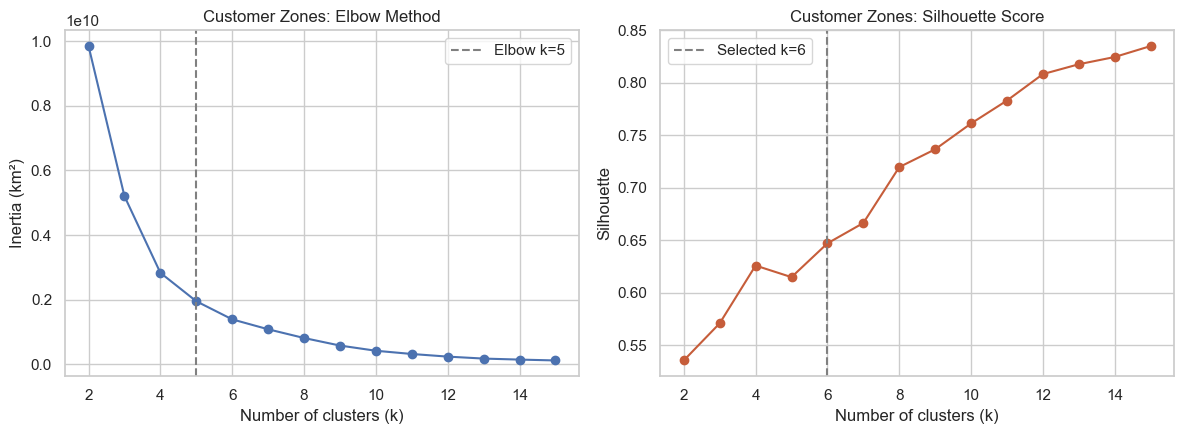

In [4]:
def evaluate_kmeans_candidates(values, k_values, sample_size, random_state):
    rows = []
    for k in k_values:
        candidate = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        candidate_labels = candidate.fit_predict(values)
        score = silhouette_score(
            values, candidate_labels,
            sample_size=min(sample_size, len(values)),
            random_state=random_state,
        )
        rows.append({
            "k": int(k),
            "inertia": float(candidate.inertia_),
            "silhouette_score": float(score),
        })
    return pd.DataFrame(rows)


def select_k_from_elbow_and_silhouette(metrics, neighborhood=1):
    '''Find a normalized inertia elbow, then use silhouette locally around it.'''
    ordered = metrics.sort_values("k").reset_index(drop=True).copy()
    if len(ordered) < 3:
        raise ValueError("At least three candidate cluster counts are needed to identify an elbow.")
    x = ordered["k"].to_numpy(dtype=float)
    inertia = ordered["inertia"].to_numpy(dtype=float)
    x_scaled = (x - x.min()) / (x.max() - x.min())
    inertia_range = inertia.max() - inertia.min()
    if inertia_range == 0:
        raise ValueError("Inertia did not change across candidate cluster counts.")
    y_scaled = (inertia - inertia.min()) / inertia_range
    ordered["elbow_distance"] = np.abs(x_scaled + y_scaled - 1) / np.sqrt(2)
    elbow_k = int(ordered.loc[ordered["elbow_distance"].idxmax(), "k"])
    nearby = ordered.loc[ordered["k"].between(elbow_k - neighborhood, elbow_k + neighborhood)]
    selected_k = int(
        nearby.sort_values(["silhouette_score", "k"], ascending=[False, True]).iloc[0]["k"]
    )
    ordered["is_elbow"] = ordered["k"].eq(elbow_k)
    ordered["selected"] = ordered["k"].eq(selected_k)
    return ordered, elbow_k, selected_k


zone_k_metrics = evaluate_kmeans_candidates(
    geo_xy, ZONE_K_VALUES, SILHOUETTE_SAMPLE_SIZE, RANDOM_STATE
)
zone_k_metrics, zone_elbow_k, selected_zone_k = select_k_from_elbow_and_silhouette(zone_k_metrics)
zone_model = KMeans(n_clusters=selected_zone_k, n_init=10, random_state=RANDOM_STATE)
geo["zone_cluster_id"] = zone_model.fit_predict(geo_xy).astype("int32")
display(zone_k_metrics)
print("Zone elbow k:", zone_elbow_k)
print("Selected zone k by silhouette within one cluster of the elbow:", selected_zone_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(zone_k_metrics["k"], zone_k_metrics["inertia"], marker="o")
axes[0].axvline(zone_elbow_k, color="gray", linestyle="--", label=f"Elbow k={zone_elbow_k}")
axes[0].set(title="Customer Zones: Elbow Method", xlabel="Number of clusters (k)", ylabel="Inertia (km²)")
axes[0].legend()
axes[1].plot(zone_k_metrics["k"], zone_k_metrics["silhouette_score"], marker="o", color="#C65D3A")
axes[1].axvline(selected_zone_k, color="gray", linestyle="--", label=f"Selected k={selected_zone_k}")
axes[1].set(title="Customer Zones: Silhouette Score", xlabel="Number of clusters (k)", ylabel="Silhouette")
axes[1].legend()
fig.tight_layout()
fig.savefig(PS6_DIR / "zone_cluster_selection.png", dpi=150)
plt.show()
plt.close(fig)

### Profile demand zones and compare with network benchmarks

Cluster demand is the number of valid-GPS orders in that cluster. Delivery time and late rate are compared with the corresponding averages across all valid-GPS orders. These are descriptive comparisons, not evidence that a location causes delivery outcomes.

In [5]:
zone_benchmark_delivery_time = float(geo["delivery_time"].mean())
zone_benchmark_late_rate = float(geo["is_late"].mean())
zone_summary = (
    geo.groupby("zone_cluster_id", as_index=False)
    .agg(
        demand_orders=("ID", "size"),
        average_delivery_time_minutes=("delivery_time", "mean"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean"),
        centroid_latitude=("latitude", "mean"),
        centroid_longitude=("longitude", "mean"),
    )
)
zone_summary["demand_share_pct"] = 100 * zone_summary["demand_orders"] / len(geo)
zone_summary["late_rate_pct"] = 100 * zone_summary["late_rate"]
zone_summary["network_average_delivery_time_minutes"] = zone_benchmark_delivery_time
zone_summary["delivery_time_delta_vs_network_minutes"] = (
    zone_summary["average_delivery_time_minutes"] - zone_benchmark_delivery_time
)
zone_summary["network_late_rate_pct"] = 100 * zone_benchmark_late_rate
zone_summary["late_rate_delta_vs_network_pp"] = (
    zone_summary["late_rate_pct"] - 100 * zone_benchmark_late_rate
)

zone_assignments = analysis[[
    "ID", "Delivery_location_latitude", "Delivery_location_longitude", "delivery_time", "is_late"
]].copy()
zone_assignments["customer_gps_valid"] = gps_valid.to_numpy(dtype=bool)
zone_assignments["zone_cluster_id"] = -1
zone_assignments.loc[geo.index, "zone_cluster_id"] = geo["zone_cluster_id"].astype(int)
zone_assignments["assignment_status"] = np.where(
    zone_assignments["customer_gps_valid"],
    "clustered_valid_customer_gps",
    "not_clustered_invalid_or_unavailable_customer_gps",
)
zone_assignments["zone_cluster_id"] = zone_assignments["zone_cluster_id"].astype("int32")

assert zone_assignments["zone_cluster_id"].notna().all()
assert zone_assignments.loc[zone_assignments["customer_gps_valid"], "zone_cluster_id"].ge(0).all()
assert zone_assignments.loc[~zone_assignments["customer_gps_valid"], "zone_cluster_id"].eq(-1).all()
assert int(zone_summary["demand_orders"].sum()) == len(geo)
assert int(zone_summary["late_orders"].sum()) == int(geo["is_late"].sum())
assert np.allclose(
    zone_summary["late_rate"],
    zone_summary["late_orders"] / zone_summary["demand_orders"],
)

display(zone_summary.sort_values("demand_orders", ascending=False).round(3))
print("Valid-GPS network benchmark — average delivery time:", round(zone_benchmark_delivery_time, 3), "minutes")
print("Valid-GPS network benchmark — late rate:", round(100 * zone_benchmark_late_rate, 2), "%")

,zone_cluster_id,demand_orders,average_delivery_time_minutes,late_orders,late_rate,centroid_latitude,centroid_longitude,demand_share_pct,late_rate_pct,network_average_delivery_time_minutes,delivery_time_delta_vs_network_minutes,network_late_rate_pct,late_rate_delta_vs_network_pp
0,0,13223,26.192,3861,0.292,12.269,77.860,31.519,29.199,26.312,-0.120,29.936,-0.737
1,1,8400,26.240,2487,0.296,22.153,74.351,20.022,29.607,26.312,-0.072,29.936,-0.329
4,4,7469,26.236,2209,0.296,18.703,73.593,17.803,29.576,26.312,-0.075,29.936,-0.360
3,3,5848,26.568,1851,0.317,27.702,76.792,13.939,31.652,26.312,0.256,29.936,1.716
2,2,3832,26.538,1181,0.308,23.587,85.432,9.134,30.819,26.312,0.227,29.936,0.884
5,5,3181,26.431,970,0.305,17.499,78.472,7.582,30.494,26.312,0.120,29.936,0.558


Valid-GPS network benchmark — average delivery time: 26.312 minutes
Valid-GPS network benchmark — late rate: 29.94 %


### Visualize the demand zones

The map uses the original geographic coordinates and K-Means labels. Cross markers show calculated centroids as potential demand-zone reference points only. Folium and Plotly are not required for execution; a Matplotlib geographic scatter plot is saved for reliable notebook and dashboard reuse.

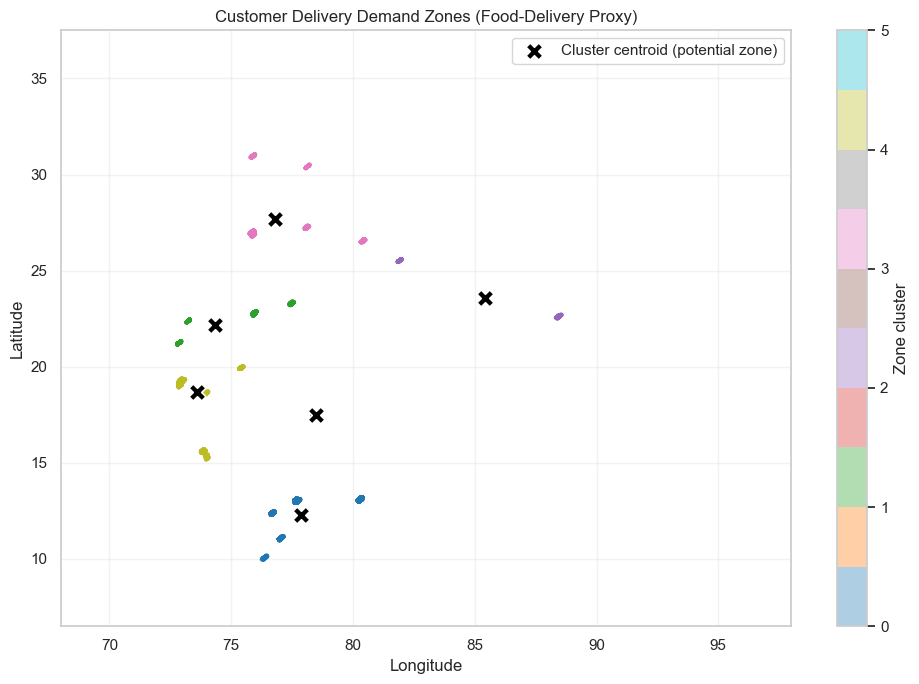

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    geo["longitude"], geo["latitude"], c=geo["zone_cluster_id"],
    cmap="tab10", s=9, alpha=0.36, linewidths=0,
)
centroids = zone_summary.sort_values("zone_cluster_id")
ax.scatter(
    centroids["centroid_longitude"], centroids["centroid_latitude"],
    marker="X", s=150, c="black", edgecolor="white", linewidth=1.2,
    label="Cluster centroid (potential zone)",
)
ax.set(
    title="Customer Delivery Demand Zones (Food-Delivery Proxy)",
    xlabel="Longitude", ylabel="Latitude",
    xlim=(68, 98), ylim=(6.5, 37.5),
)
ax.grid(alpha=0.25)
ax.legend(loc="best")
fig.colorbar(scatter, ax=ax, label="Zone cluster")
fig.tight_layout()
fig.savefig(PS6_DIR / "customer_demand_zones.png", dpi=170)
plt.show()
plt.close(fig)

### Refine broad zones into local demand hotspots with DBSCAN

The existing broad six-cluster K-Means result above is retained for comparison. DBSCAN uses only valid customer delivery coordinates, converted to radians and clustered with the Haversine metric. We inspect sorted k-distance curves for `min_samples` values 5, 10, and 15 and compare cluster/noise diagnostics. Exact repeated customer coordinates make the 5- and 10-neighbor curves predominantly zero-distance; the 15-neighbor curve provides a non-degenerate local-radius knee. The selected minimum support is therefore 15 orders, and `eps` is read from that observed knee—not set to a city-size guess. DBSCAN labels sparse points as noise and those are reported separately.

K-distance diagnostics by min_samples:


,min_samples,knee_order_rank,knee_order_percentile,knee_eps_km,zero_k_distance_pct,positive_k_distance_count
0,5,37032,88.2702,0.0501,86.0296,5861
1,10,35839,85.4265,0.0000,85.4265,6114
2,15,41037,97.8166,1.5607,47.1623,22167


Selected parameters: eps=1.5607 km (0.00024497 radians), min_samples=15.
At min_samples=15, the k-distance knee is derived from the observed sorted 15-neighbor angular distances; repeated coordinates are retained.


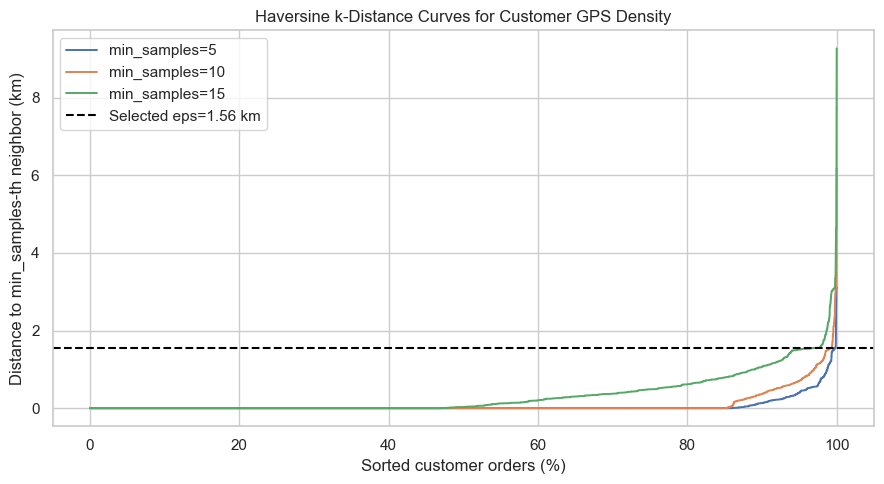

,scenario,eps_km,min_samples,cluster_count,clustered_orders,noise_orders,noise_pct,median_cluster_orders,p90_cluster_orders,largest_cluster_orders
0,min_samples sensitivity at selected eps,1.561,5,172,41903,50,0.119,29.0,602.3,3187
1,min_samples sensitivity at selected eps,1.561,10,161,41769,184,0.439,32.0,613.0,3187
2,min_samples sensitivity at selected eps,1.561,15,132,41302,651,1.552,85.5,657.9,3187
3,eps sensitivity at selected min_samples,1.249,15,303,39432,2521,6.009,27.0,222.4,3187
4,eps sensitivity at selected min_samples,1.483,15,221,39876,2077,4.951,17.0,409.0,3187
5,eps sensitivity at selected min_samples,1.561,15,132,41302,651,1.552,85.5,657.9,3187
6,eps sensitivity at selected min_samples,1.717,15,115,41378,575,1.371,87.0,927.4,3187
7,eps sensitivity at selected min_samples,1.951,15,79,41481,472,1.125,128.0,2223.4,3187


Smallest DBSCAN component: 2 orders; DBSCAN may attach border points to a component even when total component size is below min_samples, so this is reported rather than silently removed.
Connected-component extent caution: maximum 95th-percentile radius from a hotspot centroid = 11.39 km; the DBSCAN eps is a neighbor distance, not a cluster diameter.
DBSCAN demand hotspots: 132
DBSCAN density noise: 651 (1.55% of valid-GPS orders)
Invalid/unavailable GPS left unclustered: 3640
Network delivery time: 26.31 minutes
Network late rate: 29.94 %


,dbscan_cluster_id,number_of_orders,average_delivery_time_minutes,late_orders,late_rate,centroid_latitude,centroid_longitude,demand_share_pct,late_rate_pct,network_average_delivery_time_minutes,delivery_time_delta_vs_network_minutes,network_late_rate_pct,late_rate_delta_vs_network_pp,hotspot_interpretation,radius_p95_from_centroid_km,maximum_radius_from_centroid_km
18,18,3187,26.082,925,0.290,21.232,72.851,7.597,29.024,26.312,-0.230,29.936,-0.912,Observed customer delivery demand concentratio...,10.490,13.245
3,3,2615,26.184,773,0.296,11.071,77.043,6.233,29.560,26.312,-0.127,29.936,-0.376,Observed customer delivery demand concentratio...,9.965,11.487
0,0,2572,25.622,701,0.273,22.793,75.941,6.131,27.255,26.312,-0.689,29.936,-2.681,Observed customer delivery demand concentratio...,7.785,11.844
31,31,2420,26.571,757,0.313,26.975,75.867,5.768,31.281,26.312,0.259,29.936,1.345,Observed customer delivery demand concentratio...,10.230,11.798
6,6,2383,26.318,714,0.300,23.423,85.393,5.68,29.962,26.312,0.007,29.936,0.026,Observed customer delivery demand concentratio...,9.929,11.802
16,16,2260,25.846,616,0.273,13.086,80.298,5.387,27.257,26.312,-0.466,29.936,-2.679,Observed customer delivery demand concentratio...,10.461,13.273
5,5,2203,26.118,629,0.286,17.493,78.443,5.251,28.552,26.312,-0.194,29.936,-1.384,Observed customer delivery demand concentratio...,9.312,13.597
19,19,1994,26.112,559,0.280,13.011,77.687,4.753,28.034,26.312,-0.200,29.936,-1.902,Observed customer delivery demand concentratio...,10.768,13.612
34,34,1576,26.662,486,0.308,22.375,73.230,3.757,30.838,26.312,0.351,29.936,0.902,Observed customer delivery demand concentratio...,9.970,11.010
39,39,1449,25.255,375,0.259,12.377,76.672,3.454,25.880,26.312,-1.057,29.936,-4.056,Observed customer delivery demand concentratio...,6.789,8.511


,method,clusters,clustered_orders,noise_orders,selected_k_or_parameters,interpretation
0,Broad K-Means,6,41953,0,k=6,Broad geographic partitions; comparison baseline.
1,Local DBSCAN hotspots,132,41302,651,"eps=1.561 km, min_samples=15",Local density-based customer demand concentrat...


In [7]:
DBSCAN_MIN_SAMPLES_CANDIDATES = [5, 10, 15]
DBSCAN_MIN_SAMPLES = 15
DBSCAN_NOISE_LABEL = -1
INVALID_GPS_LABEL = -2
DBSCAN_EARTH_RADIUS_KM = EARTH_RADIUS_KM
geo_radians = np.radians(geo[["latitude", "longitude"]].to_numpy(dtype=float))
if not np.isfinite(geo_radians).all():
    raise AssertionError("DBSCAN input coordinates must be finite radians.")


def sorted_k_distances(coordinates_radians, min_samples):
    neighbors = NearestNeighbors(
        n_neighbors=min_samples, metric="haversine", algorithm="ball_tree", n_jobs=1
    )
    neighbors.fit(coordinates_radians)
    distances, _ = neighbors.kneighbors(coordinates_radians)
    return np.sort(distances[:, -1])


k_distance_rows = []
k_distance_curves = {}
for min_samples in DBSCAN_MIN_SAMPLES_CANDIDATES:
    sorted_distances = sorted_k_distances(geo_radians, min_samples)
    x_fraction = np.linspace(0.0, 1.0, len(sorted_distances))
    distance_range = float(sorted_distances.max() - sorted_distances.min())
    if distance_range == 0:
        knee_index = 0
        knee_eps_radians = 0.0
    else:
        normalized_distances = (sorted_distances - sorted_distances.min()) / distance_range
        knee_index = int(np.argmax(x_fraction - normalized_distances))
        knee_eps_radians = float(sorted_distances[knee_index])
    k_distance_curves[min_samples] = sorted_distances
    k_distance_rows.append({
        "min_samples": min_samples,
        "knee_order_rank": knee_index + 1,
        "knee_order_percentile": 100 * (knee_index + 1) / len(sorted_distances),
        "knee_eps_km": knee_eps_radians * DBSCAN_EARTH_RADIUS_KM,
        "zero_k_distance_pct": 100 * float((sorted_distances == 0).mean()),
        "positive_k_distance_count": int((sorted_distances > 0).sum()),
    })

k_distance_analysis = pd.DataFrame(k_distance_rows)
selected_knee_row = k_distance_analysis.loc[
    k_distance_analysis["min_samples"].eq(DBSCAN_MIN_SAMPLES)
].iloc[0]
DBSCAN_EPS_KM = float(selected_knee_row["knee_eps_km"])
DBSCAN_EPS_RADIANS = DBSCAN_EPS_KM / DBSCAN_EARTH_RADIUS_KM
if not np.isfinite(DBSCAN_EPS_KM) or DBSCAN_EPS_KM <= 0:
    raise ValueError("The selected k-distance knee must yield a positive Haversine radius.")
if DBSCAN_EPS_KM < 0.5 or DBSCAN_EPS_KM > 3.0:
    raise ValueError(
        f"Observed knee radius {DBSCAN_EPS_KM:.3f} km is outside the review range; "
        "inspect locality and coordinate quality before selecting a DBSCAN radius."
    )

print("K-distance diagnostics by min_samples:")
display(k_distance_analysis.round(4))
print(
    f"Selected parameters: eps={DBSCAN_EPS_KM:.4f} km "
    f"({DBSCAN_EPS_RADIANS:.8f} radians), min_samples={DBSCAN_MIN_SAMPLES}."
)
print(
    "At min_samples=15, the k-distance knee is derived from the observed sorted "
    "15-neighbor angular distances; repeated coordinates are retained."
)

fig, ax = plt.subplots(figsize=(9, 5))
for min_samples, distances in k_distance_curves.items():
    order_fraction = np.linspace(0, 100, len(distances))
    ax.plot(
        order_fraction, distances * DBSCAN_EARTH_RADIUS_KM,
        linewidth=1.4, label=f"min_samples={min_samples}",
    )
ax.axhline(DBSCAN_EPS_KM, color="black", linestyle="--", label=f"Selected eps={DBSCAN_EPS_KM:.2f} km")
ax.set(
    title="Haversine k-Distance Curves for Customer GPS Density",
    xlabel="Sorted customer orders (%)",
    ylabel="Distance to min_samples-th neighbor (km)",
)
ax.legend()
fig.tight_layout()
fig.savefig(PS6_DIR / "dbscan_k_distance_analysis.png", dpi=160)
plt.show()
plt.close(fig)


def dbscan_diagnostics(coordinates_radians, eps_km, min_samples, scenario):
    fitted = DBSCAN(
        eps=eps_km / DBSCAN_EARTH_RADIUS_KM,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree",
        n_jobs=1,
    )
    labels = fitted.fit_predict(coordinates_radians)
    cluster_sizes = pd.Series(labels[labels >= 0]).value_counts()
    return {
        "scenario": scenario,
        "eps_km": float(eps_km),
        "min_samples": int(min_samples),
        "cluster_count": int(cluster_sizes.size),
        "clustered_orders": int((labels >= 0).sum()),
        "noise_orders": int((labels == DBSCAN_NOISE_LABEL).sum()),
        "noise_pct": 100 * float((labels == DBSCAN_NOISE_LABEL).mean()),
        "median_cluster_orders": float(cluster_sizes.median()) if len(cluster_sizes) else 0.0,
        "p90_cluster_orders": float(cluster_sizes.quantile(0.9)) if len(cluster_sizes) else 0.0,
        "largest_cluster_orders": int(cluster_sizes.max()) if len(cluster_sizes) else 0,
    }


parameter_diagnostic_rows = []
for min_samples in DBSCAN_MIN_SAMPLES_CANDIDATES:
    parameter_diagnostic_rows.append(dbscan_diagnostics(
        geo_radians, DBSCAN_EPS_KM, min_samples, "min_samples sensitivity at selected eps"
    ))
for eps_km in sorted(set([
    DBSCAN_EPS_KM * 0.8,
    DBSCAN_EPS_KM * 0.95,
    DBSCAN_EPS_KM,
    DBSCAN_EPS_KM * 1.1,
    DBSCAN_EPS_KM * 1.25,
])):
    parameter_diagnostic_rows.append(dbscan_diagnostics(
        geo_radians, eps_km, DBSCAN_MIN_SAMPLES, "eps sensitivity at selected min_samples"
    ))
dbscan_parameter_diagnostics = pd.DataFrame(parameter_diagnostic_rows)
display(dbscan_parameter_diagnostics.round(3))

dbscan_hotspot_model = DBSCAN(
    eps=DBSCAN_EPS_RADIANS,
    min_samples=DBSCAN_MIN_SAMPLES,
    metric="haversine",
    algorithm="ball_tree",
    n_jobs=1,
)
geo["dbscan_cluster_id"] = dbscan_hotspot_model.fit_predict(geo_radians).astype("int32")
if geo["dbscan_cluster_id"].isna().any():
    raise AssertionError("DBSCAN returned missing labels.")
dbscan_noise_count = int(geo["dbscan_cluster_id"].eq(DBSCAN_NOISE_LABEL).sum())
dbscan_clustered_count = int(geo["dbscan_cluster_id"].ge(0).sum())
if dbscan_noise_count + dbscan_clustered_count != len(geo):
    raise AssertionError("DBSCAN cluster and noise counts do not reconcile.")
dbscan_component_sizes = geo.loc[
    geo["dbscan_cluster_id"].ge(0), "dbscan_cluster_id"
].value_counts()
print(
    "Smallest DBSCAN component:", int(dbscan_component_sizes.min()),
    "orders; DBSCAN may attach border points to a component even when total component "
    "size is below min_samples, so this is reported rather than silently removed."
)

hotspot_benchmark_delivery_time = float(geo["delivery_time"].mean())
hotspot_benchmark_late_rate = float(geo["is_late"].mean())
hotspot_summary = (
    geo.loc[geo["dbscan_cluster_id"].ge(0)]
    .groupby("dbscan_cluster_id", as_index=False)
    .agg(
        number_of_orders=("ID", "size"),
        average_delivery_time_minutes=("delivery_time", "mean"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean"),
        centroid_latitude=("latitude", "mean"),
        centroid_longitude=("longitude", "mean"),
    )
)
hotspot_summary["demand_share_pct"] = (
    100 * hotspot_summary["number_of_orders"] / len(geo)
)
hotspot_summary["late_rate_pct"] = 100 * hotspot_summary["late_rate"]
hotspot_summary["network_average_delivery_time_minutes"] = hotspot_benchmark_delivery_time
hotspot_summary["delivery_time_delta_vs_network_minutes"] = (
    hotspot_summary["average_delivery_time_minutes"] - hotspot_benchmark_delivery_time
)
hotspot_summary["network_late_rate_pct"] = 100 * hotspot_benchmark_late_rate
hotspot_summary["late_rate_delta_vs_network_pp"] = (
    hotspot_summary["late_rate_pct"] - 100 * hotspot_benchmark_late_rate
)
hotspot_summary["hotspot_interpretation"] = (
    "Observed customer delivery demand concentration; not a confirmed optimal store location."
)

# DBSCAN limits distances between neighboring core points, not a component's total diameter.
hotspot_extent_rows = []
for cluster_id, cluster_points in geo.loc[
    geo["dbscan_cluster_id"].ge(0)
].groupby("dbscan_cluster_id"):
    radians = np.radians(cluster_points[["latitude", "longitude"]].to_numpy(dtype=float))
    center_radians = radians.mean(axis=0)
    latitude_radians = radians[:, 0]
    delta_latitude = latitude_radians - center_radians[0]
    delta_longitude = radians[:, 1] - center_radians[1]
    haversine_a = (
        np.sin(delta_latitude / 2) ** 2
        + np.cos(latitude_radians) * np.cos(center_radians[0])
        * np.sin(delta_longitude / 2) ** 2
    )
    radius_km = 2 * DBSCAN_EARTH_RADIUS_KM * np.arcsin(
        np.sqrt(np.clip(haversine_a, 0, 1))
    )
    hotspot_extent_rows.append({
        "dbscan_cluster_id": int(cluster_id),
        "radius_p95_from_centroid_km": float(np.quantile(radius_km, 0.95)),
        "maximum_radius_from_centroid_km": float(np.max(radius_km)),
    })
hotspot_summary = hotspot_summary.merge(
    pd.DataFrame(hotspot_extent_rows), on="dbscan_cluster_id",
    how="left", validate="one_to_one",
)
if hotspot_summary[[
    "radius_p95_from_centroid_km", "maximum_radius_from_centroid_km"
]].isna().any().any():
    raise AssertionError("Hotspot centroid-radius diagnostics are incomplete.")
print(
    "Connected-component extent caution: maximum 95th-percentile radius from a hotspot centroid =",
    round(float(hotspot_summary["radius_p95_from_centroid_km"].max()), 2),
    "km; the DBSCAN eps is a neighbor distance, not a cluster diameter."
)

dbscan_hotspot_assignments = analysis[[
    "ID", "Delivery_location_latitude", "Delivery_location_longitude", "delivery_time", "is_late"
]].copy()
dbscan_hotspot_assignments["customer_gps_valid"] = gps_valid.to_numpy(dtype=bool)
dbscan_hotspot_assignments["dbscan_cluster_id"] = INVALID_GPS_LABEL
dbscan_hotspot_assignments.loc[geo.index, "dbscan_cluster_id"] = (
    geo["dbscan_cluster_id"].astype("int32")
)
dbscan_hotspot_assignments["assignment_status"] = np.select(
    [
        ~dbscan_hotspot_assignments["customer_gps_valid"],
        dbscan_hotspot_assignments["dbscan_cluster_id"].eq(DBSCAN_NOISE_LABEL),
    ],
    ["invalid_or_unavailable_customer_gps", "dbscan_noise_sparse_location"],
    default="density_based_demand_hotspot",
)
dbscan_hotspot_assignments["dbscan_cluster_id"] = (
    dbscan_hotspot_assignments["dbscan_cluster_id"].astype("int32")
)

assert dbscan_hotspot_assignments["dbscan_cluster_id"].notna().all()
assert int(hotspot_summary["number_of_orders"].sum()) == dbscan_clustered_count
assert int(hotspot_summary["late_orders"].sum()) == int(
    geo.loc[geo["dbscan_cluster_id"].ge(0), "is_late"].sum()
)
assert int(dbscan_hotspot_assignments["dbscan_cluster_id"].eq(-1).sum()) == dbscan_noise_count
assert int(dbscan_hotspot_assignments["dbscan_cluster_id"].eq(-2).sum()) == int((~gps_valid).sum())

print("DBSCAN demand hotspots:", len(hotspot_summary))
print("DBSCAN density noise:", dbscan_noise_count, f"({100 * dbscan_noise_count / len(geo):.2f}% of valid-GPS orders)")
print("Invalid/unavailable GPS left unclustered:", int((~gps_valid).sum()))
print("Network delivery time:", round(hotspot_benchmark_delivery_time, 2), "minutes")
print("Network late rate:", round(100 * hotspot_benchmark_late_rate, 2), "%")
display(hotspot_summary.sort_values("number_of_orders", ascending=False).head(20).round(3))

cluster_comparison = pd.DataFrame([
    {
        "method": "Broad K-Means",
        "clusters": int(zone_summary["zone_cluster_id"].nunique()),
        "clustered_orders": len(geo),
        "noise_orders": 0,
        "selected_k_or_parameters": f"k={selected_zone_k}",
        "interpretation": "Broad geographic partitions; comparison baseline.",
    },
    {
        "method": "Local DBSCAN hotspots",
        "clusters": len(hotspot_summary),
        "clustered_orders": dbscan_clustered_count,
        "noise_orders": dbscan_noise_count,
        "selected_k_or_parameters": f"eps={DBSCAN_EPS_KM:.3f} km, min_samples={DBSCAN_MIN_SAMPLES}",
        "interpretation": "Local density-based customer demand concentrations.",
    },
])
display(cluster_comparison)

### Geographic comparison and interactive hotspot map

The comparison preserves the original broad K-Means labels and shows DBSCAN hotspots separately from noise. The Folium map marks each hotspot centroid with demand, average delivery time, late rate, and network-relative late-rate difference; DBSCAN noise observations are shown as distinct gray points. Map centroids are not site-selection decisions. There are no verified city/locality names, so the map intentionally uses coordinates rather than assigning city names.

DBSCAN constrains distances between neighboring core points, not each component's full diameter. The exported summary reports centroid-radius diagnostics; connected components can span a wider region through density chaining. Review those extents before treating a component as a local catchment.

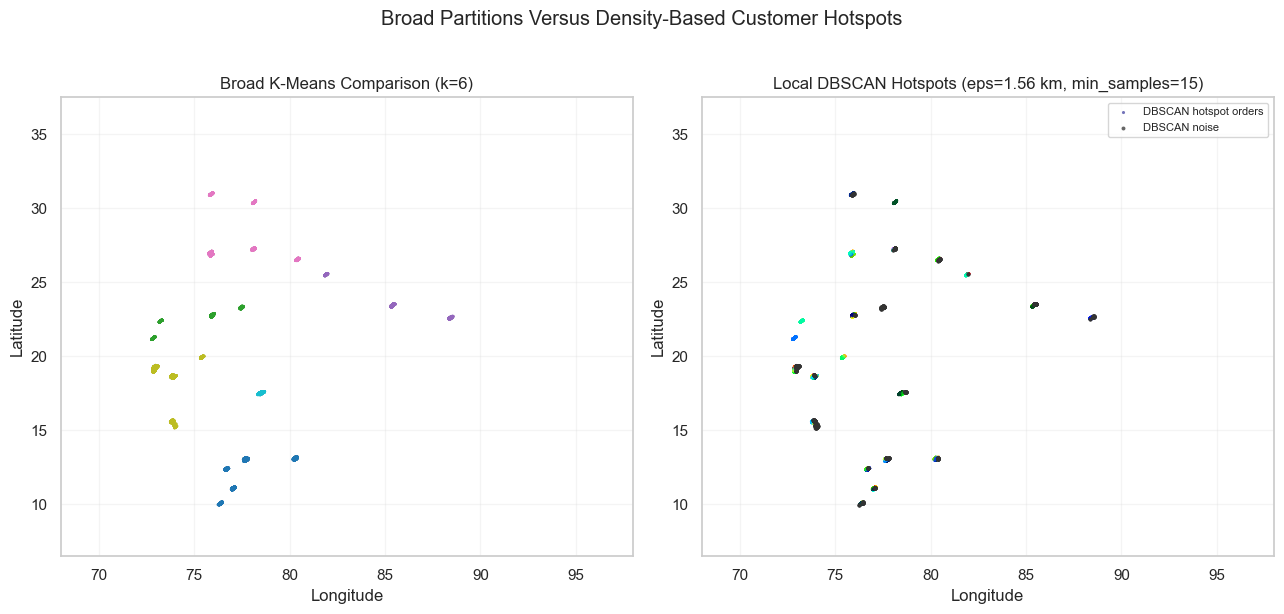

Saved interactive Folium hotspot map: C:\Users\javed\Desktop\calibo\Manthan\outputs\ps6\dbscan_hotspots_map.html


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].scatter(
    geo["longitude"], geo["latitude"], c=geo["zone_cluster_id"],
    cmap="tab10", s=5, alpha=0.45, linewidths=0,
)
axes[0].set(
    title=f"Broad K-Means Comparison (k={selected_zone_k})",
    xlabel="Longitude", ylabel="Latitude", xlim=(68, 98), ylim=(6.5, 37.5),
)

hotspot_mask = geo["dbscan_cluster_id"].ge(0)
axes[1].scatter(
    geo.loc[hotspot_mask, "longitude"], geo.loc[hotspot_mask, "latitude"],
    c=geo.loc[hotspot_mask, "dbscan_cluster_id"], cmap="gist_ncar",
    s=5, alpha=0.55, linewidths=0, label="DBSCAN hotspot orders",
)
axes[1].scatter(
    geo.loc[~hotspot_mask, "longitude"], geo.loc[~hotspot_mask, "latitude"],
    c="#333333", s=8, alpha=0.75, linewidths=0, label="DBSCAN noise",
)
axes[1].set(
    title=f"Local DBSCAN Hotspots (eps={DBSCAN_EPS_KM:.2f} km, min_samples={DBSCAN_MIN_SAMPLES})",
    xlabel="Longitude", ylabel="Latitude", xlim=(68, 98), ylim=(6.5, 37.5),
)
for ax in axes:
    ax.grid(alpha=0.2)
axes[1].legend(loc="best", fontsize=8)
fig.suptitle("Broad Partitions Versus Density-Based Customer Hotspots", y=1.02)
fig.tight_layout()
fig.savefig(PS6_DIR / "kmeans_vs_dbscan_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

hotspot_map = folium.Map(
    location=[geo_reference_latitude, geo_reference_longitude],
    zoom_start=5,
    tiles="OpenStreetMap",
    control_scale=True,
)
hotspot_layer = folium.FeatureGroup(name="DBSCAN demand hotspot centroids", show=True)
noise_layer = folium.FeatureGroup(name="DBSCAN noise / sparse orders", show=True)
for row in hotspot_summary.itertuples(index=False):
    folium.CircleMarker(
        location=[row.centroid_latitude, row.centroid_longitude],
        radius=float(np.clip(3 + np.sqrt(row.number_of_orders) / 8, 4, 17)),
        color="#9b2226",
        fill=True,
        fill_color="#ee9b00",
        fill_opacity=0.78,
        weight=1,
        tooltip=f"Hotspot {row.dbscan_cluster_id}: {row.number_of_orders:,} orders",
        popup=(
            f"<b>DBSCAN hotspot {row.dbscan_cluster_id}</b><br>"
            f"Orders: {row.number_of_orders:,}<br>"
            f"Demand share: {row.demand_share_pct:.2f}%<br>"
            f"Average delivery time: {row.average_delivery_time_minutes:.2f} min<br>"
            f"Late rate: {row.late_rate_pct:.2f}%<br>"
            f"Network late rate: {row.network_late_rate_pct:.2f}%<br>"
            f"Difference: {row.late_rate_delta_vs_network_pp:+.2f} pp<br>"
            f"95% centroid radius: {row.radius_p95_from_centroid_km:.2f} km<br>"
            "DBSCAN components may chain across a wider area; not a confirmed store site."
        ),
    ).add_to(hotspot_layer)

noise_points = geo.loc[geo["dbscan_cluster_id"].eq(DBSCAN_NOISE_LABEL)]
for row in noise_points.itertuples(index=False):
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=2,
        color="#4a4e69",
        fill=True,
        fill_color="#4a4e69",
        fill_opacity=0.55,
        weight=0.5,
        tooltip="DBSCAN noise / sparse customer order",
    ).add_to(noise_layer)

hotspot_layer.add_to(hotspot_map)
noise_layer.add_to(hotspot_map)
folium.LayerControl(collapsed=False).add_to(hotspot_map)
legend_html = f"""
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999;
background: white; padding: 10px 12px; border: 1px solid #777; font-size: 13px;">
<b>Customer demand proxy</b><br>
<span style="color:#ee9b00;">&#9679;</span> DBSCAN hotspot centroid (marker size ~ demand)<br>
<span style="color:#4a4e69;">&#9679;</span> Noise / sparse order<br>
eps={DBSCAN_EPS_KM:.3f} km; min_samples={DBSCAN_MIN_SAMPLES}<br>
Food-delivery data; not a confirmed dark-store site map
</div>
"""
hotspot_map.get_root().html.add_child(folium.Element(legend_html))
hotspot_map_path = PS6_DIR / "dbscan_hotspots_map.html"
hotspot_map.save(hotspot_map_path)
print("Saved interactive Folium hotspot map:", hotspot_map_path)

comparison_path = PS6_DIR / "kmeans_vs_dbscan_comparison.png"
cluster_comparison_path = PS6_DIR / "clustering_method_comparison.csv"
cluster_comparison.to_csv(cluster_comparison_path, index=False)

## 4. PS7 — Rider-Level Performance Segmentation

Aggregate orders by the observed rider identifier. Cluster on average rating, average delivery duration, late rate, and deliveries per active working day. Rider age is not used: professional tenure/experience is unavailable. Missing row-level ratings are excluded when calculating each rider's mean, not filled; any unavailable rider-level mean would be median-imputed inside the fitted clustering pipeline. The selected four-cluster solution has a silhouette near 0.25, indicating relatively weak separation. Treat the groups as exploratory operational profiles, not perfectly distinct rider categories.

In [9]:
rider_source = analysis.copy()
rider_source["Order_Date_parsed"] = pd.to_datetime(rider_source["Order_Date"], errors="coerce")
if rider_source["Delivery_person_ID"].isna().any():
    raise ValueError("Rider identifiers are missing; these orders cannot be assigned to rider segments.")
if rider_source["Order_Date_parsed"].isna().any():
    raise ValueError("Order dates are required to calculate rider active days.")

rider_features = (
    rider_source.groupby("Delivery_person_ID", as_index=False)
    .agg(
        average_rating=("Delivery_person_Ratings", "mean"),
        average_delivery_time_minutes=("delivery_time", "mean"),
        late_rate=("is_late", "mean"),
        delivery_count=("ID", "size"),
        active_days=("Order_Date_parsed", "nunique"),
    )
)
rider_features["deliveries_per_active_day"] = (
    rider_features["delivery_count"] / rider_features["active_days"]
)
RIDER_CLUSTER_FEATURES = [
    "average_rating", "average_delivery_time_minutes",
    "late_rate", "deliveries_per_active_day",
]
if rider_features["Delivery_person_ID"].duplicated().any():
    raise AssertionError("Rider feature aggregation must contain one row per rider.")
if not np.isfinite(
    rider_features[["average_delivery_time_minutes", "late_rate", "deliveries_per_active_day"]]
    .to_numpy(dtype=float)
).all():
    raise AssertionError("Non-rating rider cluster features contain non-finite values.")

print("Riders grouped:", len(rider_features))
print("Missing ratings in source order records (excluded from rider rating means):",
      int(rider_source["Delivery_person_Ratings"].isna().sum()))
print("Riders with unavailable mean rating (retained; model pipeline imputes):",
      int(rider_features["average_rating"].isna().sum()))
print("Rider cluster features:", RIDER_CLUSTER_FEATURES)
display(rider_features[RIDER_CLUSTER_FEATURES].describe().T.round(3))

Riders grouped: 1320
Missing ratings in source order records (excluded from rider rating means): 1961
Riders with unavailable mean rating (retained; model pipeline imputes): 0
Rider cluster features: ['average_rating', 'average_delivery_time_minutes', 'late_rate', 'deliveries_per_active_day']


,count,mean,std,min,25%,50%,75%,max
average_rating,1320.0,4.635891,0.071013,4.3,4.596261,4.635714,4.677941,4.9
average_delivery_time_minutes,1320.0,26.34754,1.938133,19.444444,25.211851,26.278689,27.461538,35.0
late_rate,1320.0,0.299904,0.096052,0.0,0.244785,0.296586,0.357143,0.7
deliveries_per_active_day,1320.0,1.589683,0.183843,1.0,1.428571,1.625,1.722222,2.0


### Select and fit rider segments

Median imputation and standardization are fitted inside a saved pipeline before K-Means. This puts rating, minutes, rate, and daily volume on comparable scales while retaining riders whose rating is unavailable. Select the normalized inertia elbow and use the best silhouette score within one `k` of that elbow. This avoids over-segmenting when silhouette alone continues to rise as clusters become more granular.

,k,inertia,silhouette_score,elbow_distance,is_elbow,selected
0,2,3689.358818,0.261525,0.000000,False,False
1,3,3070.986650,0.231421,0.123009,False,False
2,4,2611.751588,0.246647,0.184033,True,True
3,5,2364.625085,0.210094,0.162440,False,False
4,6,2149.484129,0.216220,0.128388,False,False
5,7,1998.858438,0.221893,0.069206,False,False
6,8,1873.970523,0.208712,0.000000,False,False


Rider elbow k: 4
Selected rider k by silhouette within one cluster of the elbow: 4
Selected rider silhouette=0.247; separation is relatively weak, so profiles are exploratory.


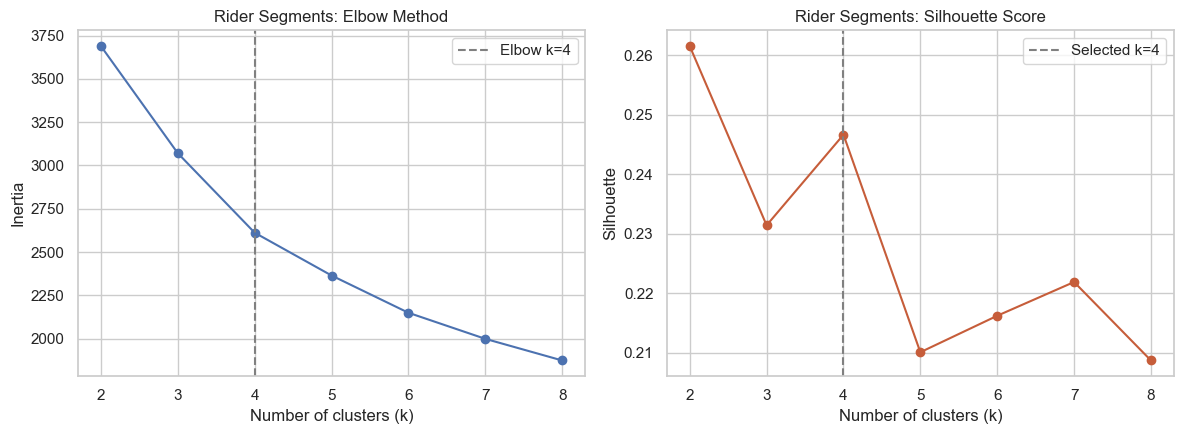

In [10]:
rider_matrix = rider_features[RIDER_CLUSTER_FEATURES]
rider_imputer = SimpleImputer(strategy="median")
rider_scaler = StandardScaler()
rider_matrix_imputed = rider_imputer.fit_transform(rider_matrix)
rider_matrix_scaled = rider_scaler.fit_transform(rider_matrix_imputed)

rider_k_metrics = evaluate_kmeans_candidates(
    rider_matrix_scaled, RIDER_K_VALUES, SILHOUETTE_SAMPLE_SIZE, RANDOM_STATE
)
rider_k_metrics, rider_elbow_k, selected_rider_k = select_k_from_elbow_and_silhouette(
    rider_k_metrics
)
rider_cluster_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=selected_rider_k, n_init=10, random_state=RANDOM_STATE)),
])
rider_features["rider_segment_id"] = rider_cluster_pipeline.fit_predict(
    rider_features[RIDER_CLUSTER_FEATURES]
).astype("int32")
display(rider_k_metrics)
print("Rider elbow k:", rider_elbow_k)
print("Selected rider k by silhouette within one cluster of the elbow:", selected_rider_k)
selected_rider_silhouette = float(rider_k_metrics.loc[rider_k_metrics["k"].eq(selected_rider_k), "silhouette_score"].iloc[0])
print(f"Selected rider silhouette={selected_rider_silhouette:.3f}; separation is relatively weak, so profiles are exploratory.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(rider_k_metrics["k"], rider_k_metrics["inertia"], marker="o")
axes[0].axvline(rider_elbow_k, color="gray", linestyle="--", label=f"Elbow k={rider_elbow_k}")
axes[0].set(title="Rider Segments: Elbow Method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[0].legend()
axes[1].plot(rider_k_metrics["k"], rider_k_metrics["silhouette_score"], marker="o", color="#C65D3A")
axes[1].axvline(selected_rider_k, color="gray", linestyle="--", label=f"Selected k={selected_rider_k}")
axes[1].set(title="Rider Segments: Silhouette Score", xlabel="Number of clusters (k)", ylabel="Silhouette")
axes[1].legend()
fig.tight_layout()
fig.savefig(PS7_DIR / "rider_cluster_selection.png", dpi=150)
plt.show()
plt.close(fig)

**Separation note:** the selected rider solution's silhouette is printed in the model-selection output and recorded in the metrics file. A value near 0.25 indicates relatively weak separation; rider groups are exploratory operational profiles rather than perfectly distinct categories.

### Profile and describe rider segments

Segment names are generated from each segment's measured averages relative to the overall rider averages. The labels summarize observed patterns only; they do not imply skill, cause, or professional experience.

In [11]:
rider_network = rider_features[RIDER_CLUSTER_FEATURES].mean(numeric_only=True)


def describe_rider_segment(row):
    descriptors = []
    descriptors.append(
        "higher late rate" if row["late_rate"] >= rider_network["late_rate"]
        else "lower late rate"
    )
    descriptors.append(
        "faster deliveries" if row["average_delivery_time_minutes"] < rider_network["average_delivery_time_minutes"]
        else "slower deliveries"
    )
    if pd.notna(row["average_rating"]):
        descriptors.append(
            "higher ratings" if row["average_rating"] >= rider_network["average_rating"]
            else "lower ratings"
        )
    descriptors.append(
        "higher daily volume" if row["deliveries_per_active_day"] >= rider_network["deliveries_per_active_day"]
        else "lower daily volume"
    )
    return ", ".join(descriptors).capitalize()


rider_segment_summary = (
    rider_features.groupby("rider_segment_id", as_index=False)
    .agg(
        rider_count=("Delivery_person_ID", "size"),
        delivery_count=("delivery_count", "sum"),
        average_rating=("average_rating", "mean"),
        average_delivery_time_minutes=("average_delivery_time_minutes", "mean"),
        late_rate=("late_rate", "mean"),
        deliveries_per_active_day=("deliveries_per_active_day", "mean"),
        average_active_days=("active_days", "mean"),
    )
)
rider_segment_summary["segment_name"] = rider_segment_summary.apply(
    describe_rider_segment, axis=1
)
rider_segment_summary["late_rate_pct"] = 100 * rider_segment_summary["late_rate"]
rider_segment_summary["network_late_rate_pct"] = (
    100 * rider_features["late_rate"].mean()
)
rider_segment_summary["late_rate_delta_vs_network_pp"] = (
    rider_segment_summary["late_rate_pct"] - rider_segment_summary["network_late_rate_pct"]
)

rider_assignments = rider_features[[
    "Delivery_person_ID", "delivery_count", "active_days",
    *RIDER_CLUSTER_FEATURES, "rider_segment_id",
]].copy()
if rider_assignments["rider_segment_id"].isna().any():
    raise AssertionError("Rider cluster assignments unexpectedly contain missing values.")
if int(rider_segment_summary["rider_count"].sum()) != rider_features["Delivery_person_ID"].nunique():
    raise AssertionError("Rider segment counts do not reconcile to unique rider records.")
if int(rider_segment_summary["delivery_count"].sum()) != len(analysis):
    raise AssertionError("Segment delivery totals do not reconcile to the source records.")

display(rider_segment_summary.sort_values("rider_count", ascending=False).round(3))

,rider_segment_id,rider_count,delivery_count,average_rating,average_delivery_time_minutes,late_rate,deliveries_per_active_day,average_active_days,segment_name,late_rate_pct,network_late_rate_pct,late_rate_delta_vs_network_pp
1,1,545,23540,4.631,26.040,0.288,1.702,25.618,"Lower late rate, faster deliveries, lower rati...",28.780,29.99,-1.211
3,3,279,8669,4.636,26.659,0.308,1.361,22.792,"Higher late rate, slower deliveries, lower rat...",30.840,29.99,0.850
0,0,265,7592,4.585,28.698,0.423,1.668,17.147,"Higher late rate, slower deliveries, lower rat...",42.284,29.99,12.294
2,2,231,5792,4.707,24.002,0.177,1.51,16.805,"Lower late rate, faster deliveries, higher rat...",17.717,29.99,-12.274


### Visualize segment characteristics

Compare the four observed rider-level features across generated segments. Values remain in their original interpretable units for these profiles; scaling is used only for clustering.

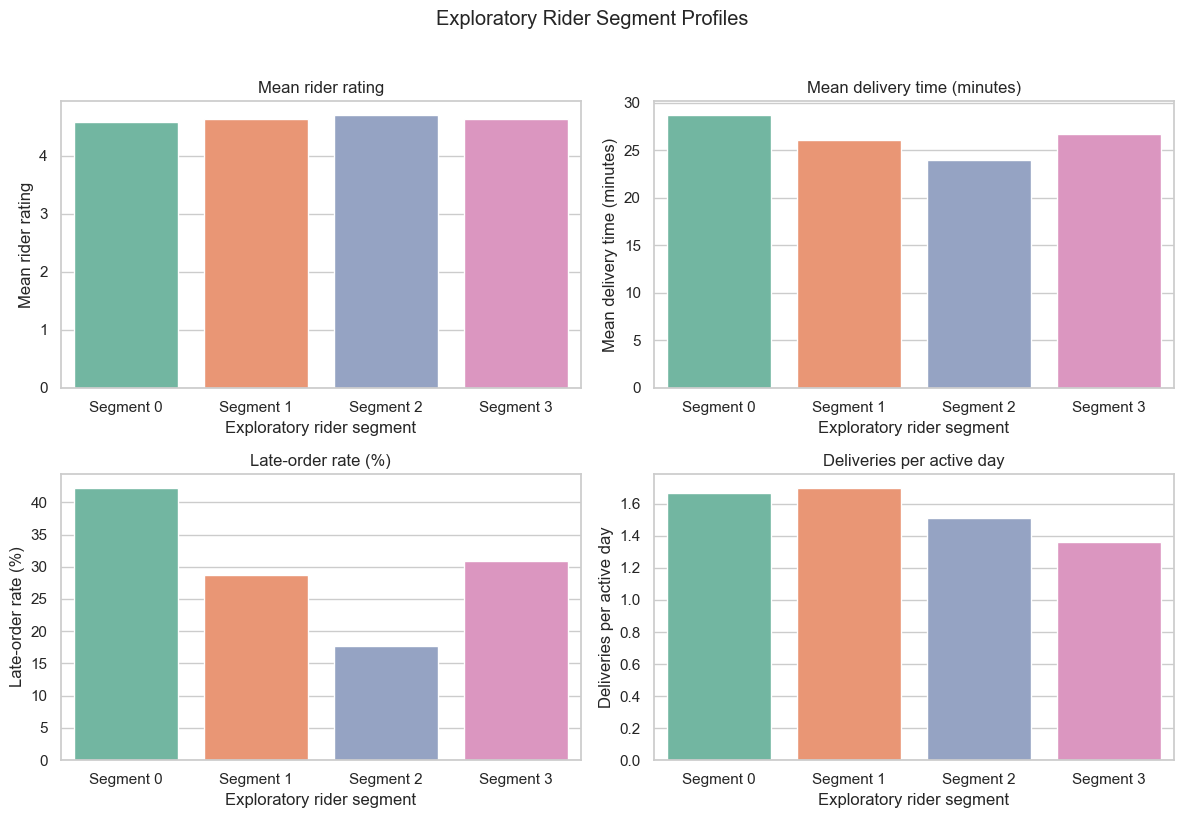

Full segment descriptions are in rider_segment_summary; chart labels are intentionally short.


,segment_label,segment_name,rider_count,delivery_count,average_rating,average_delivery_time_minutes,late_rate_pct,deliveries_per_active_day
0,Segment 0,"Higher late rate, slower deliveries, lower rat...",265,7592,4.584784,28.697810,42.284438,1.668258
1,Segment 1,"Lower late rate, faster deliveries, lower rati...",545,23540,4.630835,26.039521,28.779531,1.702084
2,Segment 2,"Lower late rate, faster deliveries, higher rat...",231,5792,4.706640,24.002120,17.716820,1.510163
3,Segment 3,"Higher late rate, slower deliveries, lower rat...",279,8669,4.635734,26.658796,30.840396,1.361325


In [12]:
profile_features = [
    ("average_rating", "Mean rider rating"),
    ("average_delivery_time_minutes", "Mean delivery time (minutes)"),
    ("late_rate_pct", "Late-order rate (%)"),
    ("deliveries_per_active_day", "Deliveries per active day"),
]
rider_segment_summary["segment_label"] = "Segment " + rider_segment_summary["rider_segment_id"].astype(str)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (feature, label) in zip(axes.flat, profile_features):
    sns.barplot(
        data=rider_segment_summary, x="segment_label", y=feature,
        order=sorted(rider_segment_summary["segment_label"].unique()),
        hue="segment_label", legend=False, palette="Set2", ax=ax,
    )
    ax.set(title=label, xlabel="Exploratory rider segment", ylabel=label)
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("Exploratory Rider Segment Profiles", y=1.02)
fig.tight_layout()
fig.savefig(PS7_DIR / "rider_segment_profiles.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Full segment descriptions are in rider_segment_summary; chart labels are intentionally short.")
display(rider_segment_summary[["segment_label", "segment_name", "rider_count", "delivery_count", "average_rating", "average_delivery_time_minutes", "late_rate_pct", "deliveries_per_active_day"]])


## 5. PS8 — Exactly Three Prioritized Management Recommendations

Recommendations are generated from the measured zone and segment summaries. Findings are descriptive, not causal. Each item includes its numerical evidence, an action, priority, and a projected—not observed—benefit. No financial or operational cost data is available to claim cost-optimality.

In [13]:
# Apply a transparent data-volume screen before ranking noisy hotspot rates:
# use the median observed DBSCAN hotspot size, not a manually selected order cutoff.
minimum_recommendation_hotspot_orders = int(hotspot_summary["number_of_orders"].median())
eligible_hotspots = hotspot_summary.loc[
    hotspot_summary["number_of_orders"].ge(minimum_recommendation_hotspot_orders)
]
highest_late_hotspot = eligible_hotspots.sort_values(
    ["late_rate", "number_of_orders"], ascending=[False, False]
).iloc[0]
highest_demand_hotspot = hotspot_summary.sort_values(
    ["number_of_orders", "late_rate"], ascending=[False, False]
).iloc[0]
highest_late_segment = rider_segment_summary.sort_values(
    ["late_rate", "rider_count"], ascending=[False, False]
).iloc[0]
highest_throughput_segment = rider_segment_summary.sort_values(
    ["deliveries_per_active_day", "rider_count"], ascending=[False, False]
).iloc[0]
selected_rider_silhouette = float(
    rider_k_metrics.loc[rider_k_metrics["k"].eq(selected_rider_k), "silhouette_score"].iloc[0]
)


def pct(value):
    return round(float(value) * 100, 2)


recommendations = [
    {
        "rank": 1,
        "priority": "High",
        "title": "Investigate the supported DBSCAN hotspot with the highest late rate",
        "observed_finding": (
            f"DBSCAN hotspot {int(highest_late_hotspot['dbscan_cluster_id'])} has the highest "
            f"late rate among hotspots with at least the data-derived median support "
            f"({minimum_recommendation_hotspot_orders} orders)."
        ),
        "supporting_evidence": {
            "source": "PS6 DBSCAN hotspot summary",
            "dbscan_cluster_id": int(highest_late_hotspot["dbscan_cluster_id"]),
            "orders": int(highest_late_hotspot["number_of_orders"]),
            "median_hotspot_support_screen_orders": minimum_recommendation_hotspot_orders,
            "late_rate_pct": pct(highest_late_hotspot["late_rate"]),
            "network_late_rate_pct": pct(hotspot_benchmark_late_rate),
            "difference_vs_network_percentage_points": round(
                float(highest_late_hotspot["late_rate_delta_vs_network_pp"]), 2
            ),
            "average_delivery_time_minutes": round(
                float(highest_late_hotspot["average_delivery_time_minutes"]), 2
            ),
            "radius_p95_from_centroid_km": round(
                float(highest_late_hotspot["radius_p95_from_centroid_km"]), 2
            ),
            "eps_km": DBSCAN_EPS_KM,
            "min_samples": DBSCAN_MIN_SAMPLES,
        },
        "operational_problem": (
            "The supported hotspot has a higher observed late rate than the valid-GPS network benchmark; "
            "the available dataset does not identify the cause."
        ),
        "recommended_management_action": (
            "Review dispatch timing, route conditions, and service coverage with local operators for this "
            "coordinate-defined hotspot. Verify the locality and current operations before changing footprint."
        ),
        "expected_benefit_projected": (
            "Projected, not observed: a local review may identify operational adjustments worth testing; "
            "measure results in a follow-up pilot before attributing any change."
        ),
    },
    {
        "rank": 2,
        "priority": "High",
        "title": "Offer non-punitive workflow support to the highest late-rate rider segment",
        "observed_finding": (
            f"Exploratory rider segment {int(highest_late_segment['rider_segment_id'])} "
            f"({highest_late_segment['segment_name']}) has the highest segment-average late rate. "
            f"The selected clustering silhouette is {selected_rider_silhouette:.3f}, indicating weak separation."
        ),
        "supporting_evidence": {
            "source": "PS7 rider segment profile",
            "rider_segment_id": int(highest_late_segment["rider_segment_id"]),
            "segment_description": str(highest_late_segment["segment_name"]),
            "riders": int(highest_late_segment["rider_count"]),
            "deliveries": int(highest_late_segment["delivery_count"]),
            "late_rate_pct": pct(highest_late_segment["late_rate"]),
            "rider_network_average_late_rate_pct": pct(rider_features["late_rate"].mean()),
            "average_delivery_time_minutes": round(
                float(highest_late_segment["average_delivery_time_minutes"]), 2
            ),
            "rider_cluster_silhouette": selected_rider_silhouette,
        },
        "operational_problem": (
            "One exploratory segment has a higher observed late rate; weak cluster separation means "
            "membership should not be treated as a definitive individual performance category."
        ),
        "recommended_management_action": (
            "Use supportive, non-punitive workflow reviews with a representative sample of riders from "
            "this segment to understand barriers; do not make individual personnel decisions from clusters."
        ),
        "expected_benefit_projected": (
            "Projected, not observed: reviewing operational barriers may suggest support improvements; "
            "assess any effect with later data and avoid causal attribution from this analysis."
        ),
    },
    {
        "rank": 3,
        "priority": "Medium",
        "title": "Pilot capacity review for the largest observed delivery hotspot",
        "observed_finding": (
            f"DBSCAN hotspot {int(highest_demand_hotspot['dbscan_cluster_id'])} contains the largest "
            f"valid-GPS order concentration ({int(highest_demand_hotspot['number_of_orders'])} orders; "
            f"{highest_demand_hotspot['demand_share_pct']:.2f}% of valid-GPS records). "
            f"The highest-throughput rider segment averages "
            f"{highest_throughput_segment['deliveries_per_active_day']:.2f} deliveries per active day."
        ),
        "supporting_evidence": {
            "source": "PS6 DBSCAN hotspot summary and PS7 rider segment profile",
            "dbscan_cluster_id": int(highest_demand_hotspot["dbscan_cluster_id"]),
            "hotspot_orders": int(highest_demand_hotspot["number_of_orders"]),
            "hotspot_demand_share_pct": round(float(highest_demand_hotspot["demand_share_pct"]), 2),
            "hotspot_late_rate_pct": pct(highest_demand_hotspot["late_rate"]),
            "hotspot_radius_p95_from_centroid_km": round(
                float(highest_demand_hotspot["radius_p95_from_centroid_km"]), 2
            ),
            "rider_segment_id": int(highest_throughput_segment["rider_segment_id"]),
            "rider_segment_count": int(highest_throughput_segment["rider_count"]),
            "deliveries_per_active_day": round(
                float(highest_throughput_segment["deliveries_per_active_day"]), 2
            ),
        },
        "operational_problem": (
            "Recorded delivery demand is geographically concentrated, but current locality-level supply "
            "and quick-commerce demand are not available in this dataset."
        ),
        "recommended_management_action": (
            "Pilot a limited staffing and service-coverage review around the largest observed hotspot, "
            "using rider throughput as context and validating local demand and current supply first."
        ),
        "expected_benefit_projected": (
            "Projected, not observed: aligning planned coverage with verified demand may improve capacity "
            "fit; quantify any effect only after a pilot using actual quick-commerce records."
        ),
    },
]
if len(recommendations) != 3:
    raise AssertionError("PS8 must produce exactly three recommendations.")
display(pd.DataFrame([
    {
        "rank": item["rank"], "priority": item["priority"],
        "recommendation": item["title"],
        "finding": item["observed_finding"],
        "operational_problem": item["operational_problem"],
        "projected_benefit": item["expected_benefit_projected"],
    }
    for item in recommendations
]))

,rank,priority,recommendation,finding,operational_problem,projected_benefit
0,1,High,Investigate the supported DBSCAN hotspot with ...,DBSCAN hotspot 52 has the highest late rate am...,The supported hotspot has a higher observed la...,"Projected, not observed: a local review may id..."
1,2,High,Offer non-punitive workflow support to the hig...,"Exploratory rider segment 0 (Higher late rate,...",One exploratory segment has a higher observed ...,"Projected, not observed: reviewing operational..."
2,3,Medium,Pilot capacity review for the largest observed...,DBSCAN hotspot 18 contains the largest valid-G...,Recorded delivery demand is geographically con...,"Projected, not observed: aligning planned cove..."


## 6. Save PS6, PS7, and PS8 Outputs

Save assignments, summaries, model-selection metrics, reusable fitted clustering models, and metadata under the existing `outputs/` and `models/` project folders. Recommendations are exported in both JSON and plain text for review and future Streamlit integration.

In [14]:
zone_assignments_path = PS6_DIR / "customer_zone_assignments.csv"
zone_summary_path = PS6_DIR / "zone_summary.csv"
zone_k_metrics_path = PS6_DIR / "cluster_selection_metrics.csv"
zone_model_path = MODEL_DIR / "ps6_customer_zone_kmeans.joblib"
zone_metadata_path = PS6_DIR / "zone_model_metadata.json"
zone_map_path = PS6_DIR / "customer_demand_zones.png"
dbscan_assignments_path = PS6_DIR / "dbscan_hotspot_assignments.csv"
hotspot_summary_path = PS6_DIR / "hotspot_summary.csv"
dbscan_model_path = MODEL_DIR / "ps6_customer_hotspot_dbscan.joblib"
dbscan_metadata_path = PS6_DIR / "dbscan_model_metadata.json"
dbscan_diagnostics_path = PS6_DIR / "dbscan_parameter_diagnostics.csv"
k_distance_path = PS6_DIR / "k_distance_analysis.csv"
hotspot_map_path = PS6_DIR / "dbscan_hotspots_map.html"
comparison_path = PS6_DIR / "kmeans_vs_dbscan_comparison.png"
cluster_comparison_path = PS6_DIR / "clustering_method_comparison.csv"
dbscan_k_distance_plot_path = PS6_DIR / "dbscan_k_distance_analysis.png"
zone_selection_plot_path = PS6_DIR / "zone_cluster_selection.png"

rider_assignments_path = PS7_DIR / "rider_segment_assignments.csv"
rider_summary_path = PS7_DIR / "rider_segment_profiles.csv"
rider_k_metrics_path = PS7_DIR / "cluster_selection_metrics.csv"
rider_model_path = MODEL_DIR / "ps7_rider_segment_pipeline.joblib"
rider_metadata_path = PS7_DIR / "rider_model_metadata.json"
rider_profile_plot_path = PS7_DIR / "rider_segment_profiles.png"
rider_selection_plot_path = PS7_DIR / "rider_cluster_selection.png"

zone_assignments.to_csv(zone_assignments_path, index=False)
zone_summary.to_csv(zone_summary_path, index=False)
zone_k_metrics.to_csv(zone_k_metrics_path, index=False)
dbscan_hotspot_assignments.to_csv(dbscan_assignments_path, index=False)
hotspot_summary.to_csv(hotspot_summary_path, index=False)
dbscan_parameter_diagnostics.to_csv(dbscan_diagnostics_path, index=False)
k_distance_analysis.to_csv(k_distance_path, index=False)
cluster_comparison.to_csv(cluster_comparison_path, index=False)
rider_assignments.to_csv(rider_assignments_path, index=False)
rider_segment_summary.to_csv(rider_summary_path, index=False)
rider_k_metrics.assign(selected=rider_k_metrics["k"].eq(selected_rider_k)).to_csv(
    rider_k_metrics_path, index=False
)

joblib.dump(zone_model, zone_model_path)
joblib.dump(rider_cluster_pipeline, rider_model_path)
joblib.dump(dbscan_hotspot_model, dbscan_model_path)

zone_metadata = {
    "comparison_role": "Original broad K-Means geographic partition, retained as PS6 comparison.",
    "model": "KMeans",
    "selected_k": selected_zone_k,
    "selection_rule": "Normalized inertia elbow, then highest silhouette within one k of the elbow.",
    "elbow_k": zone_elbow_k,
    "silhouette_search_range": [int(min(ZONE_K_VALUES)), int(max(ZONE_K_VALUES))],
    "random_state": RANDOM_STATE,
    "n_init": 10,
    "cluster_input": ["customer_delivery_latitude", "customer_delivery_longitude"],
    "coordinate_projection": "Local equirectangular projection in kilometres using mean input latitude/longitude.",
    "projection_reference_latitude": geo_reference_latitude,
    "projection_reference_longitude": geo_reference_longitude,
    "valid_customer_gps_records": len(geo),
    "unclustered_records_invalid_or_unavailable_customer_gps": int((~gps_valid).sum()),
    "centroids_are_confirmed_store_locations": False,
    "data_applicability": "Restaurant food-delivery data is a proxy for quick-commerce demand; validate with actual quick-commerce operations.",
    "benchmark_delivery_time_minutes": zone_benchmark_delivery_time,
    "benchmark_late_rate": zone_benchmark_late_rate,
}
dbscan_metadata = {
    "model": "DBSCAN",
    "metric": "haversine",
    "coordinates_converted_to_radians": True,
    "selected_eps_km": DBSCAN_EPS_KM,
    "selected_eps_radians": DBSCAN_EPS_RADIANS,
    "selected_min_samples": DBSCAN_MIN_SAMPLES,
    "min_samples_selection_evidence": (
        "min_samples=5 and 10 k-distance curves are dominated by zero distances from repeated coordinates; "
        "15-neighbor curve yields a positive observed knee and density support of 15 records."
    ),
    "eps_selection_evidence": "Sorted 15-neighbor Haversine k-distance knee converted to kilometres.",
    "selected_hotspots": len(hotspot_summary),
    "maximum_hotspot_radius_p95_from_centroid_km": float(hotspot_summary["radius_p95_from_centroid_km"].max()),
    "maximum_hotspot_radius_from_centroid_km": float(hotspot_summary["maximum_radius_from_centroid_km"].max()),
    "component_extent_caution": "eps constrains neighboring core-point distance, not full component extent; DBSCAN density connectivity can chain across a wider region.",
    "noise_orders": dbscan_noise_count,
    "noise_pct_of_valid_customer_gps": 100 * dbscan_noise_count / len(geo),
    "invalid_or_unavailable_customer_gps_orders": int((~gps_valid).sum()),
    "demand_benchmark_orders": len(geo),
    "network_average_delivery_time_minutes": hotspot_benchmark_delivery_time,
    "network_late_rate": hotspot_benchmark_late_rate,
    "centroids_are_confirmed_dark_store_sites": False,
    "geographic_label_limitation": "City values are service categories, not actual city/locality names.",
    "data_applicability": "Restaurant food-delivery coordinates are a proxy for quick-commerce demand.",
}
with dbscan_metadata_path.open("w", encoding="utf-8") as file:
    json.dump(dbscan_metadata, file, indent=2, allow_nan=False)

rider_metadata = {
    "model": "MedianImputer + StandardScaler + KMeans",
    "selected_k": selected_rider_k,
    "selection_rule": "Normalized inertia elbow, then highest silhouette within one k of the elbow.",
    "elbow_k": rider_elbow_k,
    "silhouette_search_range": [int(min(RIDER_K_VALUES)), int(max(RIDER_K_VALUES))],
    "random_state": RANDOM_STATE,
    "n_init": 10,
    "cluster_features": RIDER_CLUSTER_FEATURES,
    "grouping_identifier": "Delivery_person_ID",
    "age_used_as_professional_experience": False,
    "professional_experience_available": False,
    "source_order_records_with_missing_rating": int(rider_source["Delivery_person_Ratings"].isna().sum()),
    "riders_with_unavailable_average_rating": int(rider_features["average_rating"].isna().sum()),
    "rating_handling": (
        "Missing order-level ratings are excluded when calculating rider means. "
        "If a rider mean is unavailable, median imputation is fitted within the clustering pipeline; "
        "source ratings remain unchanged."
    ),
    "deliveries_per_day_definition": "Rider order count divided by distinct observed active order dates.",
}
with zone_metadata_path.open("w", encoding="utf-8") as file:
    json.dump(zone_metadata, file, indent=2, allow_nan=False)
with rider_metadata_path.open("w", encoding="utf-8") as file:
    json.dump(rider_metadata, file, indent=2, allow_nan=False)

recommendation_payload = {
    "exact_recommendation_count": 3,
    "basis": "Latest PS6 DBSCAN hotspot and PS7 rider segment summaries.",
    "project": "Quick-Commerce Delivery Intelligence",
    "source_data_limitation": (
        "Available records represent restaurant food delivery; use as a quick-commerce proxy only. "
        "Validate recommendations with actual quick-commerce operating data."
    ),
    "exact_recommendation_count": len(recommendations),
    "recommendations": recommendations,
}
recommendations_json_path = PS8_DIR / "recommendations.json"
recommendations_text_path = PS8_DIR / "recommendations.txt"
with recommendations_json_path.open("w", encoding="utf-8") as file:
    json.dump(recommendation_payload, file, indent=2, allow_nan=False)
with recommendations_text_path.open("w", encoding="utf-8") as file:
    file.write("PS8 — THREE PRIORITIZED MANAGEMENT RECOMMENDATIONS\n")
    file.write("=" * 54 + "\n")
    file.write(recommendation_payload["source_data_limitation"] + "\n")
    for item in recommendations:
        file.write(f"\n{item['rank']}. [{item['priority']}] {item['title']}\n")
        file.write(f"Observed finding: {item['observed_finding']}\n")
        file.write(f"Operational problem: {item['operational_problem']}\n")
        file.write("Supporting numerical evidence: ")
        file.write(json.dumps(item["supporting_evidence"], sort_keys=True) + "\n")
        file.write(f"Recommended management action: {item['recommended_management_action']}\n")
        file.write(f"Expected benefit (projected, not observed): {item['expected_benefit_projected']}\n")

print("Saved PS6 zone outputs to:", PS6_DIR)
print("Saved PS7 rider outputs to:", PS7_DIR)
print("Saved exactly three PS8 recommendations to:", PS8_DIR)

Saved PS6 zone outputs to: C:\Users\javed\Desktop\calibo\Manthan\outputs\ps6
Saved PS7 rider outputs to: C:\Users\javed\Desktop\calibo\Manthan\outputs\ps7
Saved exactly three PS8 recommendations to: C:\Users\javed\Desktop\calibo\Manthan\outputs\ps8


## 7. Streamlit Integration Manifest

The manifest lists stable relative paths, data grains, and applicability notes so a future dashboard can load the exported CSV, JSON, PNG, and model artifacts without executing this notebook.

In [15]:
manifest = {
    "manifest_version": "1.0",
    "project": "Quick-Commerce Delivery Intelligence",
    "module": "PS6-PS8",
    "sla_minutes": SLA_MINUTES,
    "sla_status": "analytical threshold; not an official customer promise",
    "dbscan_parameters": {"eps_km": DBSCAN_EPS_KM, "eps_radians": DBSCAN_EPS_RADIANS, "min_samples": DBSCAN_MIN_SAMPLES, "metric": "haversine"},
    "applicability_limitation": (
        "Restaurant food-delivery data is used as a proxy for quick-commerce operations. "
        "Clusters are demand-zone candidates, not confirmed optimal store locations. "
        "Do not generalize without validation on actual quick-commerce data."
    ),
    "rider_experience_limitation": (
        "Rider professional experience/tenure is not present; age is not used as a substitute."
    ),
    "outputs": [
        {"path": "outputs/ps6/dbscan_hotspot_assignments.csv", "grain": "one row per source order",
         "description": "Haversine DBSCAN labels; -2 invalid GPS, -1 noise, nonnegative labels hotspots."},
        {"path": "outputs/ps6/hotspot_summary.csv", "grain": "one row per DBSCAN hotspot",
         "description": "Demand, delivery time, late rate, network differences, and coordinate centroid."},
        {"path": "outputs/ps6/dbscan_parameter_diagnostics.csv", "grain": "one row per parameter scenario",
         "description": "Cluster counts, noise counts, and size diagnostics for eps/min_samples sensitivity."},
        {"path": "outputs/ps6/k_distance_analysis.csv", "grain": "one row per min_samples candidate",
         "description": "Data-derived Haversine k-distance knees and duplicate-coordinate diagnostics."},
        {"path": "outputs/ps6/dbscan_k_distance_analysis.png", "grain": "figure",
         "description": "Sorted Haversine k-distance curves and selected eps."},
        {"path": "outputs/ps6/dbscan_hotspots_map.html", "grain": "interactive map",
         "description": "Folium hotspot centroids and separately styled DBSCAN noise points."},
        {"path": "outputs/ps6/kmeans_vs_dbscan_comparison.png", "grain": "figure",
         "description": "Original broad K-Means assignments versus refined DBSCAN hotspots/noise."},
        {"path": "outputs/ps6/clustering_method_comparison.csv", "grain": "one row per method",
         "description": "Broad K-Means and local DBSCAN cluster/noise counts."},
        {"path": "outputs/ps6/dbscan_model_metadata.json", "grain": "model metadata",
         "description": "DBSCAN parameter evidence, noise, and geographic limitations."},
        {"path": "models/ps6_customer_hotspot_dbscan.joblib", "grain": "fitted estimator",
         "description": "Fitted DBSCAN training result; use metadata for input preprocessing and parameters."},
        {"path": "outputs/ps6/customer_zone_assignments.csv", "grain": "one row per source order",
         "description": "Zone labels for valid customer GPS records; -1 denotes invalid/unavailable GPS."},
        {"path": "outputs/ps6/zone_summary.csv", "grain": "one row per zone cluster",
         "description": "Demand, average time, late rate, centroid, and network benchmark comparisons."},
        {"path": "outputs/ps6/cluster_selection_metrics.csv", "grain": "one row per candidate k",
         "description": "Zone inertia and sampled silhouette scores."},
        {"path": "outputs/ps6/customer_demand_zones.png", "grain": "figure",
         "description": "Geographic demand-cluster map and candidate centroids."},
        {"path": "outputs/ps6/zone_cluster_selection.png", "grain": "figure",
         "description": "Zone elbow and silhouette diagnostics."},
        {"path": "outputs/ps6/zone_model_metadata.json", "grain": "model metadata",
         "description": "Zone model selection, coordinate projection, and limitations."},
        {"path": "models/ps6_customer_zone_kmeans.joblib", "grain": "fitted model",
         "description": "K-Means model for projected customer delivery locations."},
        {"path": "outputs/ps7/rider_segment_assignments.csv", "grain": "one row per rider",
         "description": "Rider-level observed features and cluster labels."},
        {"path": "outputs/ps7/rider_segment_profiles.csv", "grain": "one row per rider segment",
         "description": "Segment names and aggregate profiles."},
        {"path": "outputs/ps7/cluster_selection_metrics.csv", "grain": "one row per candidate k",
         "description": "Rider inertia and silhouette diagnostics."},
        {"path": "outputs/ps7/rider_segment_profiles.png", "grain": "figure",
         "description": "Segment characteristic comparison."},
        {"path": "outputs/ps7/rider_cluster_selection.png", "grain": "figure",
         "description": "Rider elbow and silhouette diagnostics."},
        {"path": "outputs/ps7/rider_model_metadata.json", "grain": "model metadata",
         "description": "Rider feature definitions, selection, and missing-rating treatment."},
        {"path": "models/ps7_rider_segment_pipeline.joblib", "grain": "fitted pipeline",
         "description": "Median imputation, scaling, and rider K-Means."},
        {"path": "outputs/ps8/recommendations.json", "grain": "exactly three recommendations",
         "description": "Prioritized evidence-based actions with projected benefits."},
        {"path": "outputs/ps8/recommendations.txt", "grain": "human-readable report",
         "description": "Three recommendations for management review."},
    ],
}
manifest_path = OUTPUT_DIR / "ps6_ps7_ps8_output_manifest.json"
with manifest_path.open("w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, allow_nan=False)
print("Saved integration manifest:", manifest_path)

Saved integration manifest: C:\Users\javed\Desktop\calibo\Manthan\outputs\ps6_ps7_ps8_output_manifest.json


## 8. Final Validation and Findings

Reload saved models, reopen exported outputs, reconcile summaries to assignments, and verify exactly three recommendations. A successful notebook run demonstrates that the generated analysis can be consumed without relying on unexecuted cells.

In [16]:
required_outputs = [
    zone_assignments_path, zone_summary_path, zone_k_metrics_path, zone_map_path,
    zone_selection_plot_path, zone_model_path, zone_metadata_path,
    dbscan_assignments_path, hotspot_summary_path, dbscan_model_path,
    dbscan_metadata_path, dbscan_diagnostics_path, k_distance_path,
    hotspot_map_path, comparison_path, cluster_comparison_path, dbscan_k_distance_plot_path,
    rider_assignments_path, rider_summary_path, rider_k_metrics_path,
    rider_profile_plot_path, rider_selection_plot_path, rider_model_path, rider_metadata_path,
    recommendations_json_path, recommendations_text_path, manifest_path,
]
missing_outputs = [
    str(path) for path in required_outputs
    if not path.is_file() or path.stat().st_size == 0
]
if missing_outputs:
    raise FileNotFoundError(f"Expected PS6-PS8 outputs are missing or empty: {missing_outputs}")

reopened_zone_assignments = pd.read_csv(zone_assignments_path)
reopened_zone_summary = pd.read_csv(zone_summary_path)
reopened_dbscan_assignments = pd.read_csv(dbscan_assignments_path)
reopened_hotspot_summary = pd.read_csv(hotspot_summary_path)
reopened_k_distance = pd.read_csv(k_distance_path)
reopened_diagnostics = pd.read_csv(dbscan_diagnostics_path)
loaded_dbscan_model = joblib.load(dbscan_model_path)
reopened_map_html = hotspot_map_path.read_text(encoding="utf-8")
with dbscan_metadata_path.open(encoding="utf-8") as file:
    reopened_dbscan_metadata = json.load(file)
reopened_rider_assignments = pd.read_csv(rider_assignments_path)
reopened_rider_summary = pd.read_csv(rider_summary_path)
with recommendations_json_path.open(encoding="utf-8") as file:
    reopened_recommendations = json.load(file)
with manifest_path.open(encoding="utf-8") as file:
    reopened_manifest = json.load(file)
loaded_zone_model = joblib.load(zone_model_path)
loaded_rider_pipeline = joblib.load(rider_model_path)

assert reopened_zone_assignments["zone_cluster_id"].notna().all()
assert reopened_dbscan_assignments["dbscan_cluster_id"].notna().all()
assert int(reopened_dbscan_assignments["dbscan_cluster_id"].eq(-1).sum()) == dbscan_noise_count
assert int(reopened_dbscan_assignments["dbscan_cluster_id"].eq(-2).sum()) == int((~gps_valid).sum())
assert int(reopened_hotspot_summary["number_of_orders"].sum()) == dbscan_clustered_count
assert reopened_hotspot_summary[["radius_p95_from_centroid_km", "maximum_radius_from_centroid_km"]].notna().all().all()
assert reopened_dbscan_metadata["maximum_hotspot_radius_p95_from_centroid_km"] == float(reopened_hotspot_summary["radius_p95_from_centroid_km"].max())
assert int(reopened_hotspot_summary["late_orders"].sum()) == int(geo.loc[geo.dbscan_cluster_id.ge(0), "is_late"].sum())
assert reopened_dbscan_metadata["metric"] == "haversine"
assert reopened_dbscan_metadata["coordinates_converted_to_radians"] is True
assert np.isclose(reopened_dbscan_metadata["selected_eps_km"], DBSCAN_EPS_KM)
assert reopened_map_html.startswith("<!DOCTYPE html>")
assert "DBSCAN noise" in reopened_map_html or "DBSCAN noise / sparse orders" in reopened_map_html
assert len(reopened_k_distance) == len(DBSCAN_MIN_SAMPLES_CANDIDATES)
assert len(reopened_diagnostics) == len(DBSCAN_MIN_SAMPLES_CANDIDATES) + 5
assert reopened_zone_assignments.loc[
    reopened_zone_assignments["customer_gps_valid"], "zone_cluster_id"
].ge(0).all()
assert reopened_zone_assignments.loc[
    ~reopened_zone_assignments["customer_gps_valid"], "zone_cluster_id"
].eq(-1).all()
assert int(reopened_zone_assignments["customer_gps_valid"].sum()) == len(geo)
assert int(reopened_zone_summary["demand_orders"].sum()) == len(geo)
assert int(reopened_zone_summary["late_orders"].sum()) == int(
    reopened_zone_assignments.loc[reopened_zone_assignments["customer_gps_valid"], "is_late"].sum()
)
assert reopened_rider_assignments["rider_segment_id"].notna().all()
assert reopened_rider_assignments["Delivery_person_ID"].is_unique
assert int(reopened_rider_summary["rider_count"].sum()) == len(reopened_rider_assignments)
assert int(reopened_rider_summary["delivery_count"].sum()) == len(analysis)
assert len(reopened_recommendations["recommendations"]) == 3
assert reopened_recommendations["exact_recommendation_count"] == 3
recommendation_report_lines = recommendations_text_path.read_text(encoding="utf-8").splitlines()
assert sum(line[:1].isdigit() and line[1:3] == ". " for line in recommendation_report_lines) == 3
assert all({"priority", "observed_finding", "supporting_evidence", "operational_problem", "recommended_management_action", "expected_benefit_projected"}.issubset(item) for item in reopened_recommendations["recommendations"])
assert all("PS6" in item["supporting_evidence"]["source"] or "PS7" in item["supporting_evidence"]["source"] for item in reopened_recommendations["recommendations"])
assert reopened_recommendations["exact_recommendation_count"] == 3
recommendation_report_lines = recommendations_text_path.read_text(encoding="utf-8").splitlines()
assert sum(line[:1].isdigit() and line[1:3] == ". " for line in recommendation_report_lines) == 3
assert len({item["rank"] for item in reopened_recommendations["recommendations"]}) == 3
assert all(
    {"observed_finding", "supporting_evidence", "recommended_management_action",
     "priority", "expected_benefit_projected"}.issubset(item)
    for item in reopened_recommendations["recommendations"]
)
assert all(item["expected_benefit_projected"].startswith("Projected, not observed:")
           for item in reopened_recommendations["recommendations"])
assert len(loaded_zone_model.labels_) == len(geo)
assert len(loaded_rider_pipeline.named_steps["kmeans"].labels_) == len(rider_features)
assert all((ROOT / item["path"]).is_file() for item in reopened_manifest["outputs"])

for image_path in [
    zone_map_path, zone_selection_plot_path, comparison_path, dbscan_k_distance_plot_path,
    rider_profile_plot_path, rider_selection_plot_path
]:
    with Image.open(image_path) as image:
        image.verify()

print("Original order records retained:", len(analysis))
print("Valid customer GPS zone records:", len(geo), "| unclustered GPS records:", int((~gps_valid).sum()))
print("Broad K-Means comparison clusters:", selected_zone_k)
print("DBSCAN parameters:", {"eps_km": DBSCAN_EPS_KM, "eps_radians": DBSCAN_EPS_RADIANS, "min_samples": DBSCAN_MIN_SAMPLES, "metric": "haversine"})
print("DBSCAN local hotspots:", len(hotspot_summary), "| noise:", dbscan_noise_count, f"({100 * dbscan_noise_count / len(geo):.2f}% of valid GPS)")
print("Selected zone clusters:", selected_zone_k, "| silhouette:",
      round(float(zone_k_metrics.loc[zone_k_metrics["k"].eq(selected_zone_k), "silhouette_score"].iloc[0]), 4))
print("Selected rider segments:", selected_rider_k, "| silhouette:",
      round(float(rider_k_metrics.loc[rider_k_metrics["k"].eq(selected_rider_k), "silhouette_score"].iloc[0]), 4))
print("Exactly three recommendations:", len(reopened_recommendations["recommendations"]))
print("Rider silhouette near 0.25 is interpreted as weak separation; labels are exploratory.")
print("All outputs reopened and reconciled:", len(required_outputs))
print("Food-delivery proxy limitation and unavailable rider experience are documented.")
print("All PS6, PS7, and PS8 validations passed.")

Original order records retained: 45593
Valid customer GPS zone records: 41953 | unclustered GPS records: 3640
Broad K-Means comparison clusters: 6
DBSCAN parameters: {'eps_km': 1.56069349119838, 'eps_radians': 0.000244968032566268, 'min_samples': 15, 'metric': 'haversine'}
DBSCAN local hotspots: 132 | noise: 651 (1.55% of valid GPS)
Selected zone clusters: 6 | silhouette: 0.6472
Selected rider segments: 4 | silhouette: 0.2466
Exactly three recommendations: 3
Rider silhouette near 0.25 is interpreted as weak separation; labels are exploratory.
All outputs reopened and reconciled: 27
Food-delivery proxy limitation and unavailable rider experience are documented.
All PS6, PS7, and PS8 validations passed.
